# 02 · EDA Bagian 3 — Biro Kredit

**Sumber data**: `bureau_observations` (798k laporan dari 3 provider), ditautkan ke aplikasi lewat `application_id`. Setiap aplikasi, baik aplikasi terpilih maupun pengajuan lama, punya 1–3 laporan biro.

| # | Pertanyaan |
|---|---|
| Q1 | Seperti apa struktur laporan biro (jumlah, provider, umur laporan, kolom kosong)? |
| Q2 | Apakah ketiga provider **konsisten**, dan bagaimana sebaiknya digabungkan? |
| Q3 | Kolom biro mana yang punya sinyal pada **laporan untuk aplikasi ini**? |
| Q4 | Apakah laporan **tanpa skor**, tanpa kredit revolving, atau laporan **basi** perlu perlakuan khusus? |
| Q5 | Kolom mana yang **berisik**, dan apakah merata-ratakan banyak laporan membantu? |
| Q6 | Apakah **perubahan skor** dari waktu ke waktu informatif? |
| Q7 | **Apa yang menentukan suku bunga?** (pertanyaan terbuka dari Bagian 1) |
| Q8 | Seberapa tumpang tindih biro dengan riwayat internal? |
| Q9 | Berapa kenaikan KS dari biro, terutama untuk **segmen tanpa riwayat**? |

Fungsi pembangun fitur sekarang ada di `features.py`, sehingga notebook Bagian 2, Bagian 3, dan tahap feature engineering memakai kode yang sama persis.

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import eda_utils as E
import features as F

E.setup_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(60)

tr = E.load("train_applications")
cp = E.load("customer_profiles")
bo = E.load("bureau_observations")
pa = E.load("previous_applications")
rh = E.load("repayment_history")
CUT = tr.select("application_id", "customer_id", pl.col("decision_datetime").alias("cutoff"))

fb = F.bureau_features(bo, CUT, income=cp.select("customer_id", "declared_monthly_income"))
cut2 = CUT.select("customer_id", "cutoff")
df = (tr.join(cp, on="customer_id", how="left")
        .join(fb, on="customer_id", how="left")
        .join(F.prev_app_features(pa, cut2), on="customer_id", how="left")
        .join(F.loan_features(pa, rh, cut2), on="customer_id", how="left")
        .join(F.repayment_features(rh, cut2), on="customer_id", how="left")
        .with_columns(
            dti=pl.col("proposed_monthly_installment") / pl.col("declared_monthly_income"),
            total_dti=(pl.col("proposed_monthly_installment") + pl.col("ln_active_installment").fill_null(0))
                      / pl.col("declared_monthly_income"),
            segment=pl.when(pl.col("pa_n").is_null()).then(pl.lit("A. tanpa riwayat"))
                      .when(pl.col("rp_n_inst").is_null()).then(pl.lit("B. ada pengajuan, belum ada cicilan"))
                      .otherwise(pl.lit("C. ada riwayat cicilan"))))
BU = [c for c in fb.columns if c.startswith("bu_")]
y = df["target"].to_numpy()
NOISE = E.ks_noise_floor(y, n_perm=200)

# laporan mentah untuk aplikasi terpilih (train), dengan target & umur laporan
sel = (bo.join(CUT, on=["application_id", "customer_id"], how="inner")
         .join(tr.select("application_id", "target", "annual_interest_rate"), on="application_id")
         .with_columns(report_age_d=F.days_between(pl.col("cutoff"), pl.col("report_datetime")),
                       publish_lag_d=F.days_between(pl.col("available_datetime"), pl.col("report_datetime"))))
print(f"{len(BU)} fitur biro | {sel.height:,} laporan untuk {sel['application_id'].n_unique():,} aplikasi train | noise floor {NOISE:.4f}")

33 fitur biro | 184,778 laporan untuk 70,000 aplikasi train | noise floor 0.0144


## Q1 · Struktur laporan biro

In [2]:
combo = (sel.group_by("application_id").agg(pl.col("bureau_provider").sort().str.join(" + ").alias("providers"))
            .group_by("providers").agg(n=pl.len()).with_columns((pl.col("n") / tr.height * 100).round(1).alias("pct"))
            .sort("n", descending=True))
display(combo)
display(sel.group_by("bureau_provider")
           .agg(n=pl.len(), score_null_pct=(pl.col("score").is_null().mean() * 100).round(2),
                util_null_pct=(pl.col("utilization").is_null().mean() * 100).round(2),
                mean_score=pl.col("score").mean().round(1), sd_score=pl.col("score").std().round(1),
                mean_active=pl.col("active_accounts").mean().round(2),
                median_outstanding=pl.col("outstanding_balance").median(),
                mean_inquiries=pl.col("inquiries_last_6m").mean().round(2),
                mean_delinquent=pl.col("delinquent_accounts_last_12m").mean().round(3))
           .sort("bureau_provider"))
print("Umur laporan saat keputusan (hari):", [int(sel["report_age_d"].quantile(q)) for q in (0, .25, .5, .75, 1)])
print("Jeda laporan dibuat → tersedia (hari):", [int(sel["publish_lag_d"].quantile(q)) for q in (0, .25, .5, .75, 1)])
print(f"Nasabah dengan laporan dari pengajuan lama: {df['bu_hist_n'].is_not_null().mean():.1%}; "
      f"median total laporan per nasabah: {df['bu_all_n'].median():.0f}")

providers,n,pct
str,u32,f64
"""Bureau_A + Bureau_B + Bureau_C""",47134,67.3
"""Bureau_A + Bureau_C""",10383,14.8
"""Bureau_A + Bureau_B""",10127,14.5
"""Bureau_A""",2356,3.4


bureau_provider,n,score_null_pct,util_null_pct,mean_score,sd_score,mean_active,median_outstanding,mean_inquiries,mean_delinquent
str,u32,f64,f64,f64,f64,f64,f64,f64,f64
"""Bureau_A""",70000,5.15,56.9,668.4,53.4,2.38,1.2871e7,1.5,0.186
"""Bureau_B""",57261,5.54,58.82,668.3,53.3,2.07,1.2255754e7,1.49,0.19
"""Bureau_C""",57517,5.8,61.19,668.3,53.4,1.79,1.1306842e7,1.51,0.189


Umur laporan saat keputusan (hari): [0, 30, 60, 90, 124]
Jeda laporan dibuat → tersedia (hari): [0, 30, 60, 90, 120]
Nasabah dengan laporan dari pengajuan lama: 70.0%; median total laporan per nasabah: 8


**Jawaban Q1.**
- Setiap aplikasi **selalu** punya laporan **Bureau_A**. Bureau_B dan Bureau_C masing-masing hadir di ~82% aplikasi (67% aplikasi punya ketiganya).
- Ketiga provider punya **skala dan sebaran skor yang identik** (rata-rata ~668, SD ~53). Laporan tanpa skor ~5–6%, dan utilisasi kosong (tidak punya limit revolving) ~57–61%.
- Umur laporan saat keputusan 0–124 hari (median 60). Jeda dari laporan dibuat sampai tersedia tersebar merata 0–120 hari. Jadi aturan `available_datetime ≤ cutoff` memang penting, meski panitia sudah menyaringnya.
- 70% nasabah juga punya **laporan masa lalu** (dari pengajuan lama), dengan median total ~8 laporan per nasabah. Ini sumber yang dimanfaatkan di Q5–Q6.

## Q2 · Apakah ketiga provider konsisten?

Kalau ketiga provider mengukur hal yang sama, nilainya di aplikasi yang sama akan berkorelasi tinggi.

kolom,corr A-B,corr A-C,corr B-C
str,f64,f64,f64
"""score""",0.815,0.815,0.815
"""outstanding_balance""",0.91,0.865,0.85
"""revolving_credit_limit""",0.822,0.789,0.771
"""active_accounts""",0.756,0.692,0.647
"""utilization""",0.664,0.665,0.657
"""inquiries_last_6m""",0.054,0.058,0.053
"""delinquent_accounts_last_12m""",0.014,0.008,0.008


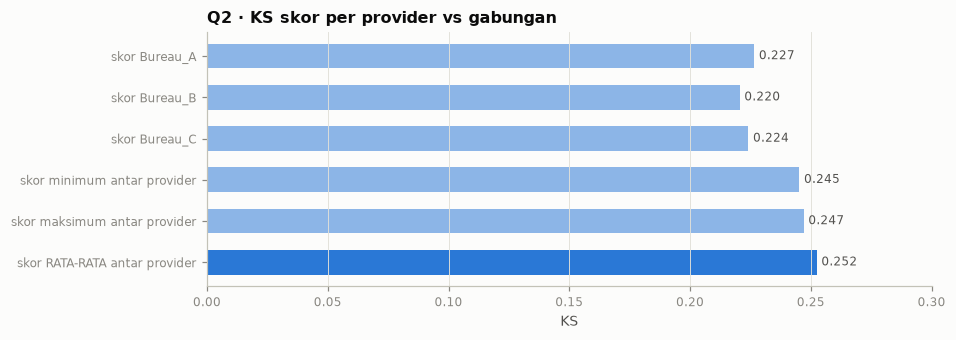

In [3]:
COLS = ["score", "outstanding_balance", "revolving_credit_limit", "active_accounts", "utilization",
        "inquiries_last_6m", "delinquent_accounts_last_12m"]
rows = []
for c in COLS:
    w = sel.pivot(on="bureau_provider", index="application_id", values=c)
    r = {"kolom": c}
    for a, b in [("Bureau_A", "Bureau_B"), ("Bureau_A", "Bureau_C"), ("Bureau_B", "Bureau_C")]:
        r[f"corr {a[-1]}-{b[-1]}"] = round(w.select(pl.corr(a, b)).item(), 3)
    rows.append(r)
agree = pl.DataFrame(rows)
display(agree)

ks_prov = []
for p in ["Bureau_A", "Bureau_B", "Bureau_C"]:
    s = sel.filter(pl.col("bureau_provider") == p)
    ks_prov.append((f"skor {p}", E.ks_stat(s["target"].to_numpy(), s["score"].to_numpy())))
for c, lab in [("bu_score_min", "skor minimum antar provider"), ("bu_score_max", "skor maksimum antar provider"),
               ("bu_score_mean", "skor RATA-RATA antar provider")]:
    ks_prov.append((lab, E.ks_stat(y, df[c].to_numpy())))
fig, ax = plt.subplots(figsize=(8.5, 3))
labs = [k[0] for k in ks_prov][::-1]
ax.barh(labs, [k[1] for k in ks_prov][::-1], color=[E.C_RATE if "RATA" in l else E.C_RATE + "88" for l in labs], height=0.6)
for i, (_, v) in enumerate(ks_prov[::-1]):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8, color=E.INK2)
ax.set_xlim(0, 0.3); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Q2 · KS skor per provider vs gabungan"); ax.set_xlabel("KS")
plt.show()

**Jawaban Q2 — kolom biro terbagi dua: yang konsisten dan yang hampir acak.**
- **Konsisten antar provider**: skor (ρ ≈ 0,81), saldo utang (~0,91), limit revolving (~0,82), jumlah akun aktif (~0,76), dan utilisasi (~0,66). Ketiga provider mengukur kondisi yang sama dengan sedikit noise.
- **Hampir tidak berkorelasi sama sekali**: `inquiries_last_6m` (ρ ≈ 0,05) dan `delinquent_accounts_last_12m` (ρ ≈ 0,01). Untuk nasabah yang sama di hari yang sama, ketiga provider melaporkan angka yang praktis independen. Nilai per laporan kolom ini sangat berisik (diuji di Q5).
- **Merata-ratakan skor dari semua provider** menaikkan KS dari ~0,22–0,23 (satu provider) menjadi **~0,25**. Ini persis yang diharapkan bila tiap provider = sinyal yang sama + noise independen.

**Implikasi fitur**: gunakan **agregat antar provider** (mean, juga min/max), bukan kolom per provider. Kehadiran Bureau_B/C bukan masalah karena rata-rata tetap terdefinisi.

## Q3 · Sinyal per kolom pada laporan untuk aplikasi ini

feature,null_pct,ks,auc,arah,iv,ks_x_noise
str,f64,f64,f64,str,f64,f64
"""bu_score_mean""",0.25,0.2524,0.3252,"""↑ nilai → ↓ risiko""",0.3961,17.5
"""bu_outstanding_max""",0.0,0.1055,0.5709,"""↑ nilai → ↑ risiko""",0.063,7.3
"""bu_outstanding_to_income""",0.0,0.1,0.5678,"""↑ nilai → ↑ risiko""",0.057,6.9
"""bu_active_max""",0.0,0.0771,0.5521,"""↑ nilai → ↑ risiko""",0.0362,5.3
"""bu_util_mean""",52.29,0.0726,0.6027,"""↑ nilai → ↑ risiko""",0.0636,5.0
"""bu_inq_mean""",0.0,0.0601,0.5412,"""↑ nilai → ↑ risiko""",0.021,4.2
"""bu_delinq_mean""",0.0,0.0522,0.5293,"""↑ nilai → ↑ risiko""",0.0145,3.6
"""bu_rev_out_max""",0.0,0.0326,0.5105,"""↑ nilai → ↑ risiko""",0.0118,2.3
"""bu_report_age_min""",0.0,0.0107,0.5042,"""↑ nilai → ↑ risiko""",0.0006,0.7


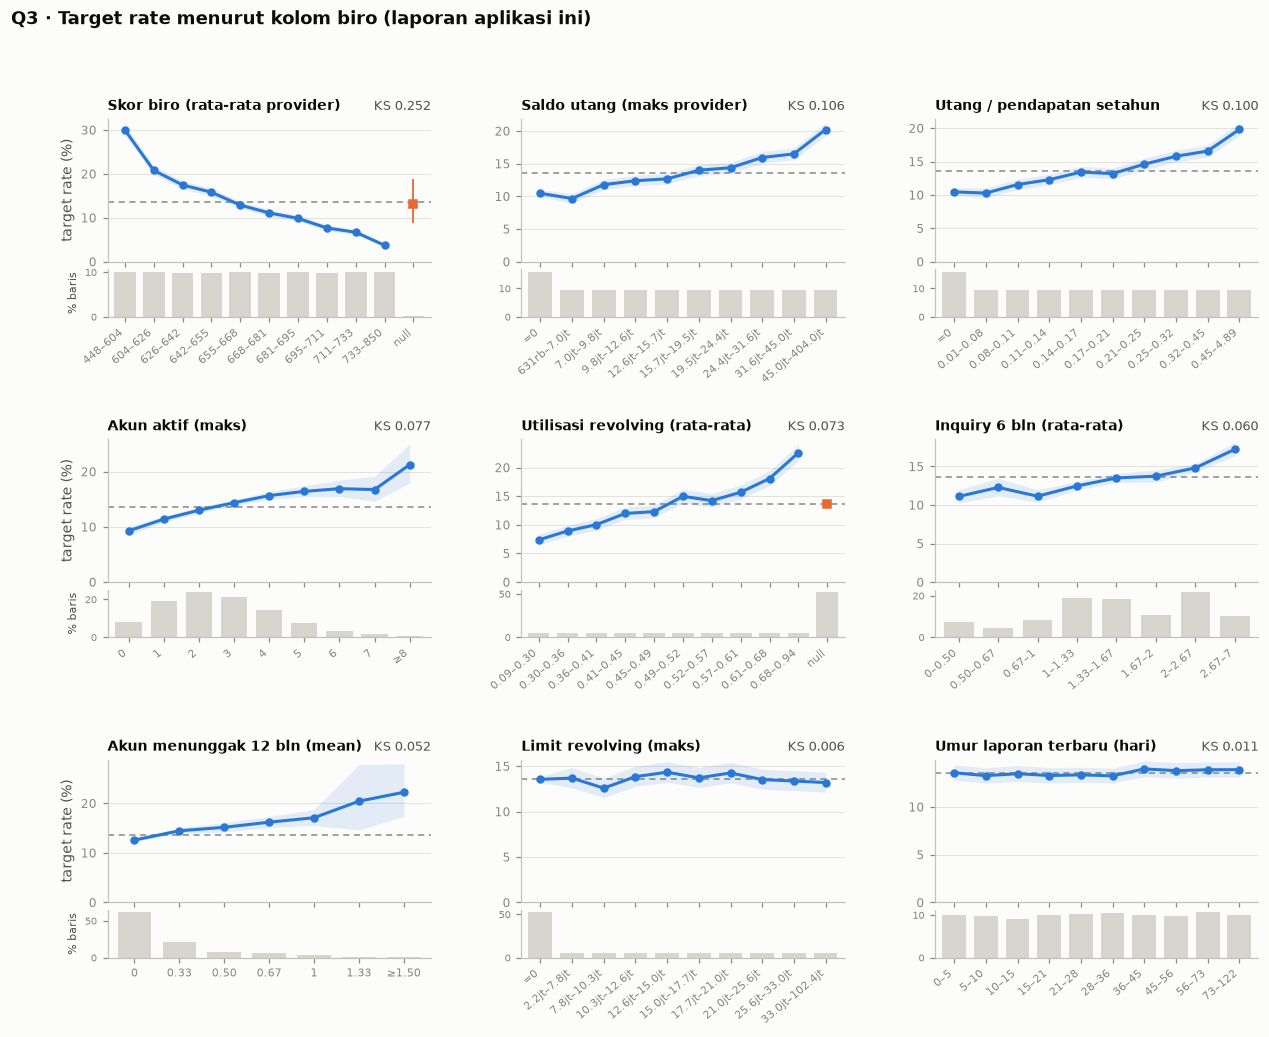

In [4]:
SNAP = ["bu_score_mean", "bu_outstanding_max", "bu_outstanding_to_income", "bu_active_max", "bu_util_mean",
        "bu_inq_mean", "bu_delinq_mean", "bu_rev_limit_max", "bu_rev_out_max", "bu_has_revolving",
        "bu_n_unscored", "bu_n_reports", "bu_report_age_min"]
sig = E.signal_table(df, SNAP).with_columns((pl.col("ks") / NOISE).round(1).alias("ks_x_noise"))
display(sig.select("feature", "null_pct", "ks", "auc", "arah", "iv", "ks_x_noise"))
E.plot_rates(df, ["bu_score_mean", "bu_outstanding_max", "bu_outstanding_to_income", "bu_active_max", "bu_util_mean",
                  "bu_inq_mean", "bu_delinq_mean", "bu_rev_limit_max", "bu_report_age_min"],
             titles={"bu_score_mean": "Skor biro (rata-rata provider)", "bu_outstanding_max": "Saldo utang (maks provider)",
                     "bu_outstanding_to_income": "Utang / pendapatan setahun", "bu_active_max": "Akun aktif (maks)",
                     "bu_util_mean": "Utilisasi revolving (rata-rata)", "bu_inq_mean": "Inquiry 6 bln (rata-rata)",
                     "bu_delinq_mean": "Akun menunggak 12 bln (mean)", "bu_rev_limit_max": "Limit revolving (maks)",
                     "bu_report_age_min": "Umur laporan terbaru (hari)"},
             suptitle="Q3 · Target rate menurut kolom biro (laporan aplikasi ini)")

**Jawaban Q3.**
- **Skor biro** adalah sinyal terkuat di tabel ini (KS ~0,25, sedikit di atas suku bunga). Default rate turun tajam dan monoton seiring naiknya skor.
- **Saldo utang** (KS ~0,10–0,11) dan rasionya terhadap pendapatan (~0,10) adalah sinyal sekunder yang jelas: makin besar utang di tempat lain, makin berisiko.
- **Akun aktif** (~0,08) dan **utilisasi** (~0,07; null bila tak punya revolving) sinyal sedang. **Inquiry** dan **akun menunggak** pada laporan ini lemah (~0,05–0,06), karena berisik (Q2, Q5).
- **Limit revolving**, ada/tidaknya revolving, jumlah laporan, jumlah laporan tanpa skor, dan umur laporan ≈ **noise**.

## Q4 · Laporan tanpa skor, tanpa revolving, dan laporan basi

tanpa_skor,n,target_rate
bool,u32,f64
false,174665,0.1359
true,10113,0.131


bu_has_revolving,n,target_rate
bool,u32,f64
false,36600,0.1355
true,33400,0.1361


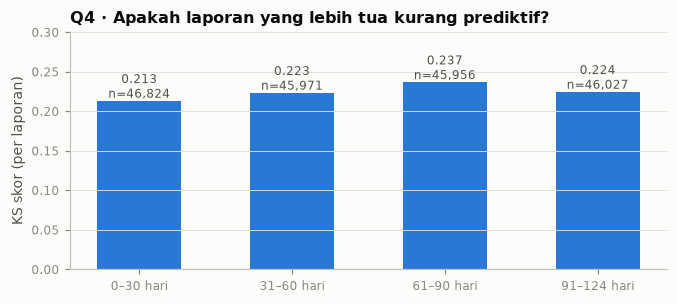

In [5]:
display(sel.group_by(pl.col("score").is_null().alias("tanpa_skor"))
           .agg(n=pl.len(), target_rate=pl.col("target").mean().round(4)).sort("tanpa_skor"))
display(df.group_by("bu_has_revolving").agg(n=pl.len(), target_rate=pl.col("target").mean().round(4)).sort("bu_has_revolving"))
age_ks = []
for lo, hi in [(0, 30), (31, 60), (61, 90), (91, 200)]:
    s = sel.filter(pl.col("report_age_d").is_between(lo, hi))
    age_ks.append((f"{lo}–{hi if hi < 200 else '124'} hari", E.ks_stat(s["target"].to_numpy(), s["score"].to_numpy()), s.height))
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar([a[0] for a in age_ks], [a[1] for a in age_ks], color=E.C_RATE, width=0.55)
for i, a in enumerate(age_ks):
    ax.text(i, a[1] + 0.004, f"{a[1]:.3f}\nn={a[2]:,}", ha="center", fontsize=8, color=E.INK2)
ax.set_ylim(0, 0.3); ax.set_ylabel("KS skor (per laporan)")
ax.set_title("Q4 · Apakah laporan yang lebih tua kurang prediktif?")
plt.show()

**Jawaban Q4 — tidak ada yang perlu perlakuan khusus.**
- **Laporan tanpa skor tidak lebih berisiko** (~13,1% vs ~13,6%). Ini berbeda dengan dunia nyata (*thin file*), jadi tidak perlu flag khusus. Cukup biarkan skor rata-rata dihitung dari provider yang punya skor.
- **Punya/tidak punya kredit revolving** juga tidak membedakan risiko. Utilisasi baru bermakna **bila** ada limit, jadi null-nya biarkan apa adanya.
- **Umur laporan tidak menurunkan daya prediksi**: KS skor laporan berumur 0–30 hari sama dengan laporan berumur > 90 hari (~0,21–0,24). Fitur "keterbaruan" tidak diperlukan.

## Q5 · Kolom berisik & manfaat merata-ratakan banyak laporan

Di Q2, inquiry dan akun menunggak antar provider hampir tidak berkorelasi. Kalau setiap laporan = "kecenderungan sebenarnya + noise besar", maka **merata-ratakan lebih banyak laporan** (termasuk laporan dari pengajuan lama) seharusnya menaikkan KS. Kita uji dengan mengelompokkan nasabah menurut jumlah total laporan biro yang dimilikinya.

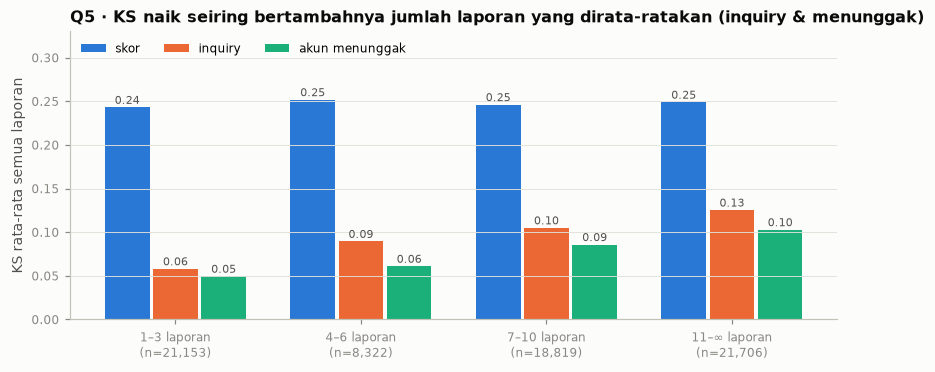

feature,null_pct,ks,auc
str,f64,f64,f64
"""bu_score_mean""",0.25,0.2524,0.3252
"""bu_all_score_mean""",0.09,0.2448,0.3295
"""bu_all_inq_mean""",0.0,0.0962,0.5617
"""bu_hist_inq_mean""",30.0,0.0954,0.563
"""bu_hist_delinq_mean""",30.0,0.0817,0.5492
"""bu_all_delinq_mean""",0.0,0.0801,0.551
"""bu_inq_mean""",0.0,0.0601,0.5412
"""bu_delinq_mean""",0.0,0.0522,0.5293


In [6]:
groups = [(1, 3), (4, 6), (7, 10), (11, 99)]
series = {"skor": "bu_all_score_mean", "inquiry": "bu_all_inq_mean", "akun menunggak": "bu_all_delinq_mean"}
vals = {k: [] for k in series}
ns = []
for lo, hi in groups:
    s = df.filter(pl.col("bu_all_n").is_between(lo, hi))
    ns.append(s.height)
    for k, c in series.items():
        vals[k].append(E.ks_stat(s["target"].to_numpy(), s[c].to_numpy()))
fig, ax = plt.subplots(figsize=(9, 3.4))
xs = np.arange(len(groups)); wbar = 0.26
for j, (k, v) in enumerate(vals.items()):
    ax.bar(xs + (j - 1) * wbar, v, width=wbar - 0.02, color=E.SERIES[j], label=k)
    for i, val in enumerate(v):
        ax.text(xs[i] + (j - 1) * wbar, val + 0.004, f"{val:.2f}", ha="center", fontsize=7, color=E.INK2)
ax.set_xticks(xs); ax.set_xticklabels([f"{lo}–{hi if hi < 99 else '∞'} laporan\n(n={n:,})" for (lo, hi), n in zip(groups, ns)])
ax.set_ylabel("KS rata-rata semua laporan"); ax.set_ylim(0, 0.33); ax.legend(loc="upper left", ncols=3)
ax.set_title("Q5 · KS naik seiring bertambahnya jumlah laporan yang dirata-ratakan (inquiry & menunggak)")
plt.show()
cmp = E.signal_table(df, ["bu_inq_mean", "bu_hist_inq_mean", "bu_all_inq_mean",
                          "bu_delinq_mean", "bu_hist_delinq_mean", "bu_all_delinq_mean",
                          "bu_score_mean", "bu_all_score_mean"])
cmp.select("feature", "null_pct", "ks", "auc")

**Jawaban Q5 — ya, untuk inquiry dan akun menunggak, lebih banyak laporan = sinyal lebih bersih.**
- KS inquiry naik dari ~0,06 (1–3 laporan) ke ~0,13 (> 10 laporan). KS akun menunggak naik dari ~0,05 ke ~0,10. Sebaliknya, KS **skor** hampir konstan (~0,24–0,25), karena skor sudah merupakan ringkasan yang stabil.
- Akibatnya, **rata-rata seluruh laporan** (`bu_all_inq_mean` ~0,10, `bu_all_delinq_mean` ~0,08) jauh lebih kuat daripada laporan aplikasi ini saja (~0,06 dan ~0,05).
- Catatan: kenaikan ini sebagian juga dipengaruhi perbedaan populasi (nasabah dengan banyak laporan = nasabah lama). Tapi polanya konsisten dengan dugaan noise di Q2.

**Implikasi fitur**: untuk kolom berisik, agregasikan **semua laporan sebelum cutoff** (bukan hanya laporan terbaru) dan sertakan `bu_all_n` agar model tahu seberapa andal rata-ratanya. Ini mirip temuan "seluruh riwayat > jendela pendek" di Bagian 2.

## Q6 · Apakah perubahan skor informatif?

48,850 nasabah punya skor sekarang & skor dari laporan lama | korelasi skor sekarang vs rata-rata skor lama: 0.924


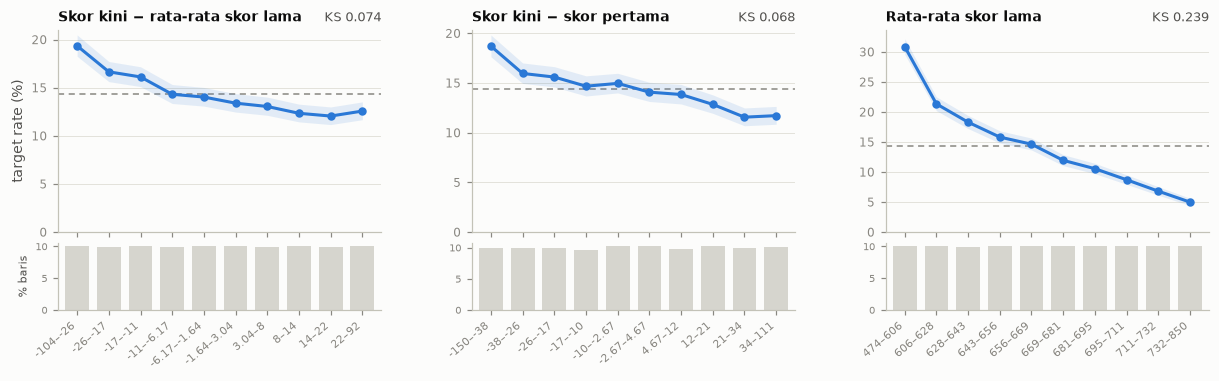

C:\Users\TUF\AppData\Local\Temp\ipykernel_15680\4030683325.py:7: DeprecationWarning: `qcut` is deprecated; use `bin_quantiles` or `bin_ranks` instead
  s_tr, _ = E.ks_within(hist_sub.with_columns(sb=pl.col("bu_score_mean").qcut(5, allow_duplicates=True).cast(pl.String)),


Tren skor DI DALAM kuintil skor sekarang: {'feature': 'bu_score_trend', 'ks_overall': 0.0745, 'ks_within': 0.0328, 'noise_within': 0.0441, 'excess_within': -0.0113}


In [7]:
hist_sub = df.filter(pl.col("bu_score_trend").is_not_null())
print(f"{hist_sub.height:,} nasabah punya skor sekarang & skor dari laporan lama | "
      f"korelasi skor sekarang vs rata-rata skor lama: {hist_sub.select(pl.corr('bu_score_mean', 'bu_hist_score_mean', method='spearman')).item():.3f}")
E.plot_rates(hist_sub, ["bu_score_trend", "bu_score_change_first", "bu_hist_score_mean"], ncols=3,
             titles={"bu_score_trend": "Skor kini − rata-rata skor lama", "bu_score_change_first": "Skor kini − skor pertama",
                     "bu_hist_score_mean": "Rata-rata skor lama"})
s_tr, _ = E.ks_within(hist_sub.with_columns(sb=pl.col("bu_score_mean").qcut(5, allow_duplicates=True).cast(pl.String)),
                      "bu_score_trend", "sb", n_perm=30)
print("Tren skor DI DALAM kuintil skor sekarang:", {k: round(v, 4) if isinstance(v, float) else v for k, v in s_tr.items()})

**Jawaban Q6 — perubahan skor hampir tidak menambah informasi.**
- Skor sangat stabil dari waktu ke waktu (ρ ≈ 0,92 antara skor sekarang dan rata-rata skor lama).
- Tren skor punya KS ~0,05–0,07 secara mentah, tapi **di dalam kelompok skor sekarang yang sama**, KS-nya di bawah noise. Sinyal tren sepenuhnya berasal dari level skor saat ini, jadi skor yang **membaik** tidak membuat nasabah lebih aman daripada skor *saat ini*-nya.
- Fitur tren skor bisa dilewati. Level skor saat ini (dan rata-rata semua laporan) sudah cukup.

## Q7 · Apa yang menentukan suku bunga?

Bagian 1: profil tidak menentukan bunga. Bagian 2: riwayat bayar hanya sedikit ikut menentukan. Sekarang kita uji skor biro.

C:\Users\TUF\AppData\Local\Temp\ipykernel_15680\248003709.py:1: DeprecationWarning: `qcut` is deprecated; use `bin_quantiles` or `bin_ranks` instead
  d7 = df.drop_nulls("bu_score_mean").with_columns(score_decile=pl.col("bu_score_mean").qcut(10, labels=[f"D{i}" for i in range(1, 11)]).cast(pl.String))


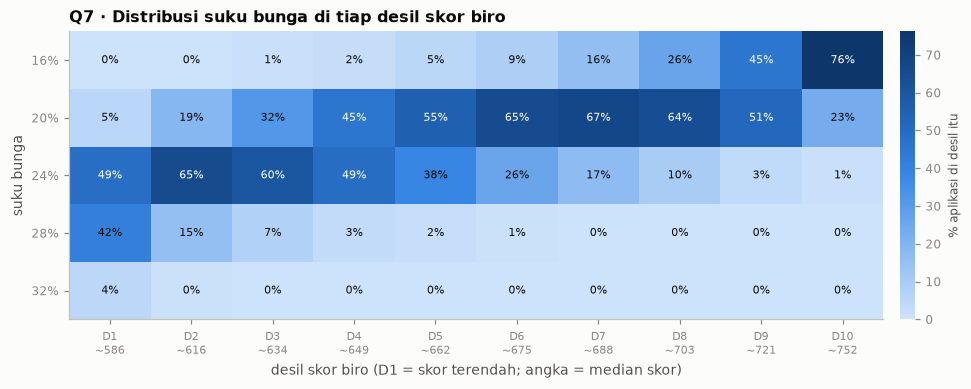

Spearman suku bunga vs skor biro: -0.736


In [8]:
d7 = df.drop_nulls("bu_score_mean").with_columns(score_decile=pl.col("bu_score_mean").qcut(10, labels=[f"D{i}" for i in range(1, 11)]).cast(pl.String))
rates = [0.16, 0.20, 0.24, 0.28, 0.32]
deciles = [f"D{i}" for i in range(1, 11)]
M = np.array([[d7.filter((pl.col("score_decile") == d) & (pl.col("annual_interest_rate") == r)).height /
               max(d7.filter(pl.col("score_decile") == d).height, 1) * 100 for d in deciles] for r in rates])
med = [d7.filter(pl.col("score_decile") == d)["bu_score_mean"].median() for d in deciles]
fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(M, cmap=E.SEQ_CMAP, aspect="auto")
ax.grid(False)
ax.set_xticks(range(10)); ax.set_xticklabels([f"{d}\n~{m:.0f}" for d, m in zip(deciles, med)], fontsize=7.5)
ax.set_yticks(range(5)); ax.set_yticklabels([f"{int(r*100)}%" for r in rates])
for i in range(5):
    for j in range(10):
        ax.text(j, i, f"{M[i,j]:.0f}%", ha="center", va="center", fontsize=7.5, color="white" if M[i, j] > 45 else E.INK)
ax.set_xlabel("desil skor biro (D1 = skor terendah; angka = median skor)"); ax.set_ylabel("suku bunga")
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02); cb.set_label("% aplikasi di desil itu", fontsize=8); cb.outline.set_visible(False)
ax.set_title("Q7 · Distribusi suku bunga di tiap desil skor biro")
plt.show()
print("Spearman suku bunga vs skor biro:", round(d7.select(pl.corr("annual_interest_rate", "bu_score_mean", method="spearman")).item(), 3))

In [9]:
import warnings
import lightgbm as lgb
from sklearn.model_selection import cross_val_predict, StratifiedKFold
rate_cls = (df["annual_interest_rate"] * 100).round().cast(pl.Int32).to_numpy()
acc = []
for name, feats in [("skor biro saja", ["bu_score_mean"]),
                    ("semua fitur biro", BU),
                    ("riwayat internal saja", [c for c in df.columns if c.startswith(("pa_", "ln_", "rp_")) and c != "pa_last_decision"]),
                    ("biro + riwayat + profil + nominal", BU + [c for c in df.columns if c.startswith(("pa_", "ln_", "rp_")) and c != "pa_last_decision"]
                                                          + ["loan_amount", "declared_monthly_income", "age", "employment_tenure_months", "dependents"])]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pred = cross_val_predict(lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, verbose=-1),
                                 df.select(feats).to_pandas(), rate_cls, cv=StratifiedKFold(5, shuffle=True, random_state=0))
    acc.append(dict(prediktor=name, akurasi_tepat=round((pred == rate_cls).mean(), 3),
                    akurasi_selisih_maks_1_tingkat=round((np.abs(pred - rate_cls) <= 4).mean(), 3)))
acc.append(dict(prediktor="(selalu tebak 20%)", akurasi_tepat=round(np.bincount(rate_cls).max() / len(rate_cls), 3),
                akurasi_selisih_maks_1_tingkat=None))
display(pl.DataFrame(acc))
r1, _ = E.ks_within(d7, "annual_interest_rate", "score_decile", n_perm=30)
r2, _ = E.ks_within(df, "bu_score_mean", "annual_interest_rate", n_perm=30)
pl.DataFrame([dict(pertanyaan="info suku bunga DI LUAR skor (strata = desil skor)", **{k: v for k, v in r1.items() if k != "feature"}),
              dict(pertanyaan="info skor DI LUAR suku bunga (strata = suku bunga)", **{k: v for k, v in r2.items() if k != "feature"})]
            ).with_columns(pl.col(pl.Float64).round(4))

prediktor,akurasi_tepat,akurasi_selisih_maks_1_tingkat
str,f64,f64
"""skor biro saja""",0.614,0.991
"""semua fitur biro""",0.61,0.991
"""riwayat internal saja""",0.493,0.956
"""biro + riwayat + profil + nominal""",0.627,0.993
"""(selalu tebak 20%)""",0.426,null


pertanyaan,ks_overall,ks_within,noise_within,excess_within
str,f64,f64,f64,f64
"""info suku bunga DI LUAR skor (strata = desil skor)""",0.2305,0.057,0.0495,0.0075
"""info skor DI LUAR suku bunga (strata = suku bunga)""",0.2524,0.1379,0.0312,0.1068


**Jawaban Q7 — suku bunga pada dasarnya adalah versi kasar + berisik dari skor biro.**
- Korelasi suku bunga dengan skor biro **ρ ≈ −0,74**. Heatmap menunjukkan pergeseran yang rapi: desil skor terendah didominasi bunga 24–28%, desil tertinggi didominasi 16–20%.
- Skor biro saja menebak suku bunga dengan tepat ~61% (vs 43% kalau selalu menebak 20%), dan **~99% selisihnya maksimal satu tingkat**. Menambah fitur biro lain, riwayat internal, dan profil hampir tidak menambah akurasi (~62–63%). Sisanya terlihat seperti **noise acak** dalam penetapan harga.
- Uji dua arah:
  - Di dalam desil skor yang sama, suku bunga hampir **tidak** membawa info tambahan (excess ≈ 0,01).
  - Di dalam kelompok bunga yang sama, skor masih membawa **banyak** info (excess ≈ 0,11).

➡️ Jawaban pertanyaan terbuka Bagian 1: **lender menetapkan bunga dari skor biro**, dibulatkan ke 5 tingkat dengan noise. Riwayat bayar internal yang jauh lebih prediktif (Bagian 2) justru **kurang dipakai** lender, dan itulah sumber keunggulan model kita. Konsekuensinya, KS 0,23 dari suku bunga di Bagian 1 sebenarnya adalah "bayangan" dari skor biro.

## Q8 · Tumpang tindih biro dengan riwayat internal

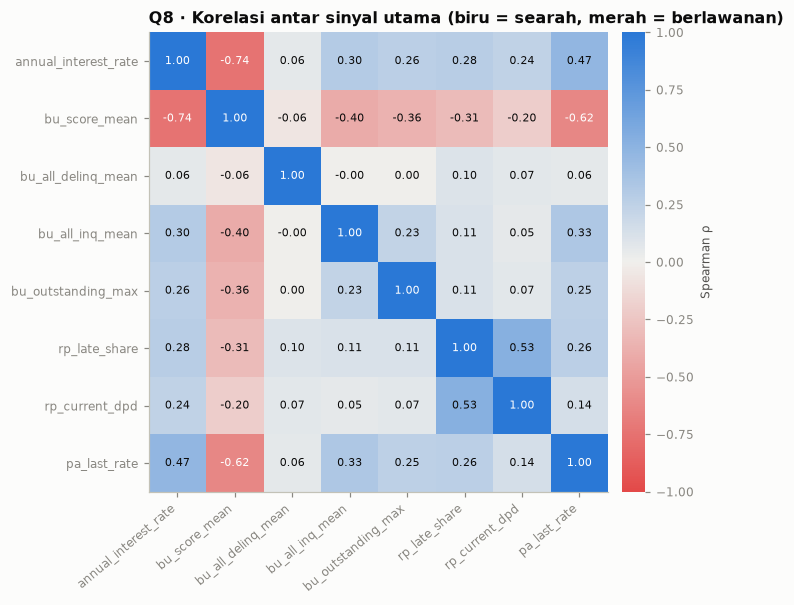

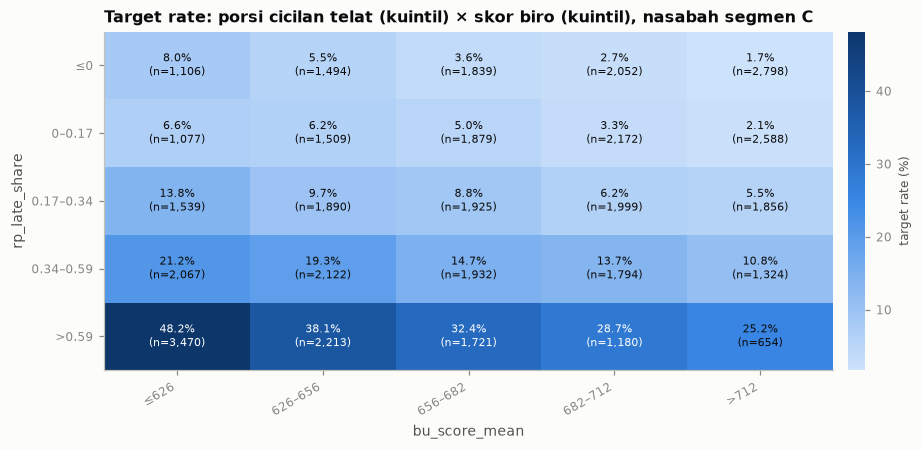

In [10]:
KEYS = ["annual_interest_rate", "bu_score_mean", "bu_all_delinq_mean", "bu_all_inq_mean", "bu_outstanding_max",
        "rp_late_share", "rp_current_dpd", "pa_last_rate"]
corr = df.select(KEYS).to_pandas().corr(method="spearman").round(2)
fig, ax = plt.subplots(figsize=(7.5, 5.6))
diverge = plt.matplotlib.colors.LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
im = ax.imshow(corr.values, cmap=diverge, vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(KEYS))); ax.set_xticklabels(KEYS, rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(KEYS))); ax.set_yticklabels(KEYS, fontsize=8)
for i in range(len(KEYS)):
    for j in range(len(KEYS)):
        ax.text(j, i, f"{corr.values[i,j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(corr.values[i, j]) > 0.6 else E.INK)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("Spearman ρ", fontsize=8); cb.outline.set_visible(False)
ax.set_title("Q8 · Korelasi antar sinyal utama (biru = searah, merah = berlawanan)")
plt.tight_layout(); plt.show()
c_sub = df.filter(pl.col("rp_late_share").is_not_null() & pl.col("bu_score_mean").is_not_null())
E.heatmap_rate(c_sub, "rp_late_share", "bu_score_mean", row_bins=5, col_bins=5,
               title="Target rate: porsi cicilan telat (kuintil) × skor biro (kuintil), nasabah segmen C", figsize=(9, 4))

**Jawaban Q8 — biro dan riwayat internal sebagian besar saling melengkapi.**
- Skor biro sangat dekat dengan **suku bunga** (|ρ| ≈ 0,74) dan **bunga pinjaman lama** (~0,62), karena keduanya "turunan" skor (Q7). Dengan **porsi cicilan telat**, korelasinya hanya ~0,31.
- Heatmap menunjukkan **kedua sumber sama-sama bekerja**: di setiap kuintil skor biro, default rate tetap naik tajam seiring porsi telat (skor ≤ 626: 8% → 48%; skor > 712: 1,7% → 25%), dan sebaliknya. Kombinasi terburuk (skor rendah + sering telat, ~48%) jauh lebih berisiko daripada masing-masing sendirian.
- Akun menunggak & inquiry di biro hanya berkorelasi lemah dengan riwayat telat internal. Keduanya mengukur perilaku **di lender lain**.

## Q9 · Kontribusi biro terhadap KS (keseluruhan & per segmen)

config,n_features,ks_oof,auc_oof,ks_seg_A,ks_seg_B,ks_seg_C
str,i64,f64,f64,f64,f64,f64
"""1. patokan (aplikasi + profil)""",12,0.228,0.6455,0.1935,0.2367,0.243
"""2. + riwayat internal (Bagian 2)""",59,0.3959,0.776,0.1978,0.1989,0.4911
"""3. patokan + biro""",45,0.2732,0.6894,0.2543,0.2573,0.2804
"""4. + riwayat internal + biro""",92,0.4181,0.787,0.2487,0.2671,0.4945


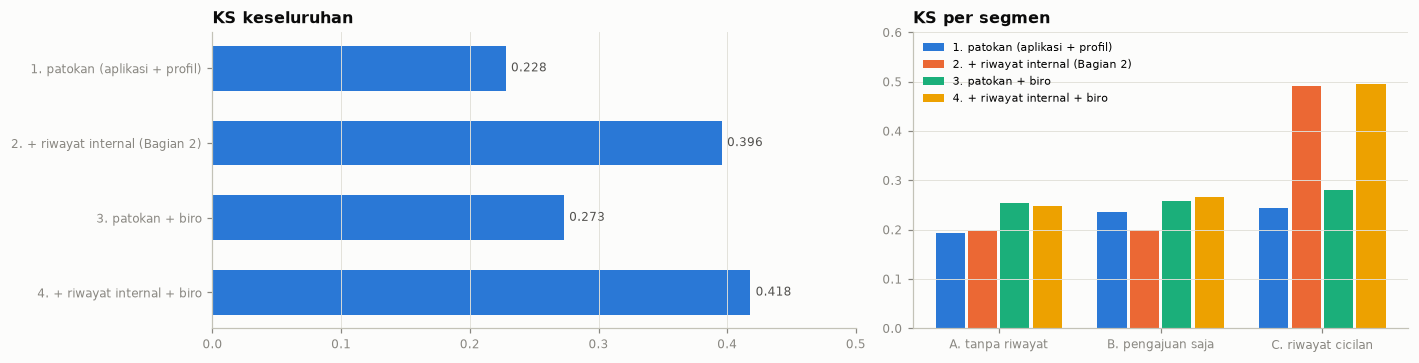

In [11]:
CATS = ["loan_purpose", "region", "employment_type", "housing_status", "segment"]
BASE = ["annual_interest_rate", "loan_amount", "proposed_monthly_installment", "loan_purpose", "age", "region",
        "employment_type", "employment_tenure_months", "declared_monthly_income", "dependents", "housing_status", "dti"]
INTERNAL = [c for c in df.columns if c.startswith(("pa_", "ln_", "rp_")) and c != "pa_last_decision"] + ["total_dti", "segment"]
configs = {
    "1. patokan (aplikasi + profil)": BASE,
    "2. + riwayat internal (Bagian 2)": BASE + INTERNAL,
    "3. patokan + biro": BASE + BU,
    "4. + riwayat internal + biro": BASE + INTERNAL + BU,
}
res, oofs, imps = [], {}, {}
for name, feats in configs.items():
    oof, ks, auc, imp = E.cv_lgb(df, feats, cat_features=[c for c in CATS if c in feats])
    scored = df.select("segment", "target").with_columns(oof=pl.Series(oof))
    seg = {k[0][:1]: round(E.ks_stat(g["target"].to_numpy(), g["oof"].to_numpy()), 4) for k, g in scored.group_by("segment")}
    res.append(dict(config=name, n_features=len(feats), ks_oof=round(ks, 4), auc_oof=round(auc, 4),
                    ks_seg_A=seg["A"], ks_seg_B=seg["B"], ks_seg_C=seg["C"]))
    oofs[name], imps[name] = oof, imp
res = pl.DataFrame(res)
display(res)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.barh(res["config"].to_list()[::-1], res["ks_oof"].to_list()[::-1], color=E.C_RATE, height=0.6)
for i, v in enumerate(res["ks_oof"].to_list()[::-1]):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8, color=E.INK2)
ax.set_xlim(0, 0.5); ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.set_title("KS keseluruhan")
ax = axes[1]
segs = ["ks_seg_A", "ks_seg_B", "ks_seg_C"]; lab = ["A. tanpa riwayat", "B. pengajuan saja", "C. riwayat cicilan"]
xs = np.arange(3); wbar = 0.2
for j, row in enumerate(res.iter_rows(named=True)):
    ax.bar(xs + (j - 1.5) * wbar, [row[s] for s in segs], width=wbar - 0.02, color=E.SERIES[j], label=row["config"][:34])
ax.set_xticks(xs); ax.set_xticklabels(lab); ax.set_ylim(0, 0.6); ax.set_title("KS per segmen")
ax.legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()

In [12]:
imps["4. + riwayat internal + biro"].head(20).with_columns(pl.col("gain_pct").round(2))

feature,gain_pct
str,f64
"""rp_late_share""",30.81
"""rp_mean_dpd""",10.13
"""bu_all_score_mean""",6.43
"""ln_remaining_amount""",4.19
"""rp_paid_ratio""",2.95
"""bu_score_mean""",2.7
"""rp_late_share_365d""",2.5
"""rp_n_inst""",2.35
"""ln_total_approved""",2.08


**Jawaban Q9.**
- **Biro saja** (tanpa riwayat internal) menaikkan KS patokan dari ~0,23 ke ~0,27. Kenaikannya kecil karena skor biro sudah "tercermin" di suku bunga.
- **Riwayat internal + biro** → KS ~**0,42**, naik ~0,02 di atas riwayat internal saja (~0,40).
- Kenaikan terbesar justru di tempat yang paling dibutuhkan: **segmen A (tanpa riwayat)** naik dari ~0,19–0,20 menjadi **~0,25**, dan segmen B juga ~0,25. Untuk segmen C, biro hanya menambah sedikit (~0,49 → ~0,50) karena riwayat bayar internal sudah jauh lebih kuat.
- Importance: setelah `rp_late_share` & `rp_mean_dpd`, fitur biro teratas adalah varian **skor** (mean/min/max).

**Status setelah Bagian 3**: KS ≈ 0,42 secara keseluruhan; segmen tanpa riwayat ≈ 0,25. Segmen A masih tertinggal jauh dari segmen C (~0,50). Dua sumber terakhir, **rekening** (hanya ada untuk nasabah lama!) dan **e-commerce** (ada untuk ~100% nasabah), akan dinilai dari kemampuannya menutup gap ini.

## Ringkasan Bagian 3

| Temuan | Implikasi untuk feature engineering |
|---|---|
| Bureau_A selalu ada; B & C ~82%; skala skor ketiganya identik | Agregasi antar provider (mean/min/max), bukan kolom per provider |
| Skor & saldo utang konsisten antar provider; inquiry & akun menunggak **hampir acak** per laporan | Kolom berisik → **rata-rata semua laporan sebelum cutoff** + jumlah laporan |
| Skor rata-rata provider (KS ~0,25) > skor satu provider (~0,22–0,23) | Pakai `bu_score_mean` (+ min/max) |
| Saldo utang (KS ~0,10) & rasio utang/pendapatan sinyal sekunder | Masukkan; kandidat untuk "total beban utang" |
| Laporan tanpa skor, tanpa revolving, umur laporan ≈ tidak informatif | Tidak perlu flag khusus; biarkan null apa adanya |
| Tren skor tidak menambah info di luar skor saat ini | Lewati fitur tren skor |
| **Suku bunga ≈ skor biro yang dibulatkan + noise** | Bunga & skor saling menggantikan; keunggulan model ada di **riwayat bayar internal** yang kurang dipakai lender |
| Biro mengangkat segmen tanpa riwayat: KS ~0,20 → ~0,25 | Biro adalah fondasi untuk segmen A/B |
| KS keseluruhan ~0,40 → **~0,42** | Patokan untuk Bagian 4 (rekening) & 5 (e-commerce) |